In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load prepared dataset
df = pd.read_csv("../data/processed/orders_prepared.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Convert recorded lead time to numeric
df["Shipping Lead Time"] = pd.to_numeric(
    df["Shipping Lead Time"], errors="coerce"
)

# Validate required columns
required_columns = [
    "Order Key",
    "Factory",
    "Ship Mode",
    "Shipping Lead Time",
    "Cost",
    "Sales"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("Dataset shape:", df.shape)
print("Missing required columns:", missing_columns)
print("\nShipping modes:")
print(df["Ship Mode"].value_counts(dropna=False))

print("\nMissing lead times:", df["Shipping Lead Time"].isna().sum())
print("Unique orders:", df["Order Key"].nunique())

if "Cost" in df.columns:
    print("Cost field available: product cost, not shipping cost")


Dataset shape: (10194, 36)
Missing required columns: []

Shipping modes:
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

Missing lead times: 0
Unique orders: 5111
Cost field available: product cost, not shipping cost


In [2]:

# Create a unique order-factory shipment identifier
df["Shipment_ID"] = (
    df["Order Key"].astype(str)
    + "_"
    + df["Factory"].astype(str)
)

# Aggregate performance by shipping mode
ship_mode_summary = (
    df.groupby("Ship Mode")
    .agg(
        Total_Shipments=("Shipment_ID", "nunique"),
        Mean_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median"),
        Std_Lead_Time=("Shipping Lead Time", "std"),
        Min_Lead_Time=("Shipping Lead Time", "min"),
        Max_Lead_Time=("Shipping Lead Time", "max")
    )
    .reset_index()
)

# Calculate shipment share
total_shipments = ship_mode_summary["Total_Shipments"].sum()

ship_mode_summary["Shipment_Share_Percent"] = (
    ship_mode_summary["Total_Shipments"] / total_shipments
) * 100

# Calculate coefficient of variation
ship_mode_summary["Lead_Time_CV_Percent"] = (
    ship_mode_summary["Std_Lead_Time"]
    / ship_mode_summary["Mean_Lead_Time"].replace(0, np.nan)
) * 100

# Round numerical metrics
numeric_cols = ship_mode_summary.select_dtypes(
    include="number"
).columns

ship_mode_summary[numeric_cols] = (
    ship_mode_summary[numeric_cols].round(2)
)

# Rank by mean recorded lead time
ship_mode_summary = ship_mode_summary.sort_values(
    "Mean_Lead_Time"
).reset_index(drop=True)

print("Total order-factory shipments:", total_shipments)
print("\nShipping mode performance:")
display(ship_mode_summary)


Total order-factory shipments: 6958

Shipping mode performance:


,Ship Mode,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Shipment_Share_Percent,Lead_Time_CV_Percent
0,Standard Class,4162,1314.33,1274.0,262.40,908,1642,59.82,19.96
1,Second Class,1351,1323.85,1273.0,261.81,906,1640,19.42,19.78
2,Same Day,358,1333.44,1269.0,253.81,904,1636,5.15,19.03
3,First Class,1087,1338.28,1272.0,265.63,905,1638,15.62,19.85


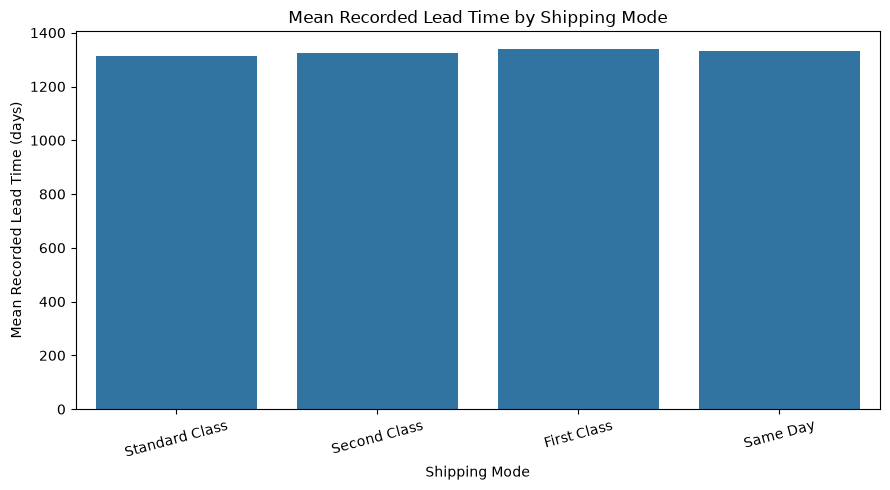

In [3]:

# Compare mean recorded lead time across shipping modes

plt.figure(figsize=(9, 5))

sns.barplot(
    data=ship_mode_summary,
    x="Ship Mode",
    y="Mean_Lead_Time",
    order=[
        "Standard Class",
        "Second Class",
        "First Class",
        "Same Day"
    ]
)

plt.title("Mean Recorded Lead Time by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Mean Recorded Lead Time (days)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


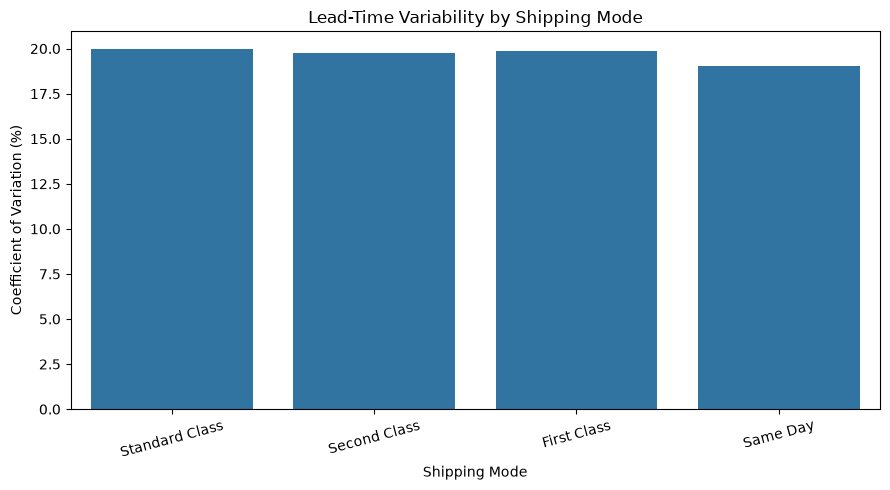

In [4]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=ship_mode_summary,
    x="Ship Mode",
    y="Lead_Time_CV_Percent",
    order=[
        "Standard Class",
        "Second Class",
        "First Class",
        "Same Day"
    ]
)

plt.title("Lead-Time Variability by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Coefficient of Variation (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



## Cost Time Trade-off Assessment

The analysis compared recorded lead-time performance across Standard Class, Second Class, First Class, and Same Day shipping. Standard Class had the lowest mean recorded lead time (1,314.33 days), while First Class had the highest (1,338.28 days), a difference of 23.95 days. Same Day showed the lowest coefficient of variation (19.03%), whereas Standard Class showed the highest (19.96%), although the differences in variability were small.

A direct cost–time trade-off could not be established because the available `Cost` field represents product cost rather than shipping charges. Actual freight-cost data would be required to determine whether faster shipping modes involve higher transportation costs. Furthermore, the unusually large recorded lead times must be validated against the source dates before these results can be interpreted as actual shipping performance.


In [5]:

from pathlib import Path

# Create output directory if it doesn't exist
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Export shipping-mode performance summary
output_path = output_dir / "ship_mode_performance_summary.csv"

ship_mode_summary.to_csv(output_path, index=False)

print("Ship mode summary exported successfully!")
print("Saved to:", output_path)
print("Rows exported:", len(ship_mode_summary))

display(ship_mode_summary)


Ship mode summary exported successfully!
Saved to: ..\data\processed\ship_mode_performance_summary.csv
Rows exported: 4


,Ship Mode,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Shipment_Share_Percent,Lead_Time_CV_Percent
0,Standard Class,4162,1314.33,1274.0,262.40,908,1642,59.82,19.96
1,Second Class,1351,1323.85,1273.0,261.81,906,1640,19.42,19.78
2,Same Day,358,1333.44,1269.0,253.81,904,1636,5.15,19.03
3,First Class,1087,1338.28,1272.0,265.63,905,1638,15.62,19.85
